In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from sklearn.metrics import classification_report
import torch.nn as nn

import experiment
import clslib
import analysis
import mmlp

In [2]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [3]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

indicator_encoder = clslib.TokenIndicator(bpe_tokenizer)

my_classifiers = OrderedDict()

In [4]:
hidden_dim=128
hidden_dim_2=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['modMLP_indic-enc'] = []

for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/modMLP_indic-enc/seed-{seed}"

    my_classifiers['modMLP_indic-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=indicator_encoder,
            model_option='mmlp',
            save_to=run_folder,
            mmlp_args={
                'hidden_dim': hidden_dim,
                'hidden_dim_2': hidden_dim_2,
                'dropout': dropout,
                'batch_size': batch_size,
                'learning_rate': learning_rate,
                'weight_decay': weight_decay,
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 21.487 seconds
Dataloader done! Time taken: 0.601 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\PCUser\Desktop\UvA\NLP\NLP-Assignment-1\mmlp.py:75: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.4826 | train acc: 0.7603 | val loss: 0.3812 | val acc: 0.8272
Epoch 02 | train loss: 0.3128 | train acc: 0.8660 | val loss: 0.2977 | val acc: 0.8763
Epoch 03 | train loss: 0.2167 | train acc: 0.9144 | val loss: 0.2731 | val acc: 0.8944
Epoch 04 | train loss: 0.1634 | train acc: 0.9377 | val loss: 0.2627 | val acc: 0.9032
Epoch 05 | train loss: 0.1279 | train acc: 0.9519 | val loss: 0.2629 | val acc: 0.9088
Epoch 06 | train loss: 0.1044 | train acc: 0.9617 | val loss: 0.2820 | val acc: 0.9118
Epoch 07 | train loss: 0.0873 | train acc: 0.9676 | val loss: 0.2889 | val acc: 0.9121
Epoch 08 | train loss: 0.0751 | train acc: 0.9726 | val loss: 0.3068 | val acc: 0.9116
Epoch 09 | train loss: 0.0658 | train acc: 0.9758 | val loss: 0.3163 | val acc: 0.9128
Epoch 10 | train loss: 0.0583 | train acc: 0.9784 | val loss: 0.3470 | val acc: 0.9120
Training done! Time taken: 105.877 seconds
Transforming documents...
Document transformation done! Time taken: 21.434 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4866 | train acc: 0.7574 | val loss: 0.3887 | val acc: 0.8301
Epoch 02 | train loss: 0.3119 | train acc: 0.8669 | val loss: 0.3099 | val acc: 0.8729
Epoch 03 | train loss: 0.2171 | train acc: 0.9143 | val loss: 0.2840 | val acc: 0.8902
Epoch 04 | train loss: 0.1600 | train acc: 0.9390 | val loss: 0.2738 | val acc: 0.8996
Epoch 05 | train loss: 0.1247 | train acc: 0.9528 | val loss: 0.2885 | val acc: 0.9040
Epoch 06 | train loss: 0.1021 | train acc: 0.9626 | val loss: 0.3027 | val acc: 0.9029
Epoch 07 | train loss: 0.0849 | train acc: 0.9689 | val loss: 0.3341 | val acc: 0.9040
Epoch 08 | train loss: 0.0737 | train acc: 0.9731 | val loss: 0.3299 | val acc: 0.9086
Epoch 09 | train loss: 0.0640 | train acc: 0.9767 | val loss: 0.3548 | val acc: 0.9086
Epoch 10 | train loss: 0.0574 | train acc: 0.9791 | val loss: 0.3718 | val acc: 0.9081
Training done! Time taken: 100.313 seconds
Transforming documents...
Document transformation done! Time taken: 21.746 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4849 | train acc: 0.7575 | val loss: 0.3887 | val acc: 0.8252
Epoch 02 | train loss: 0.3093 | train acc: 0.8695 | val loss: 0.3061 | val acc: 0.8743
Epoch 03 | train loss: 0.2151 | train acc: 0.9147 | val loss: 0.2779 | val acc: 0.8909
Epoch 04 | train loss: 0.1596 | train acc: 0.9380 | val loss: 0.2880 | val acc: 0.8967
Epoch 05 | train loss: 0.1275 | train acc: 0.9521 | val loss: 0.2833 | val acc: 0.9024
Epoch 06 | train loss: 0.1020 | train acc: 0.9618 | val loss: 0.3016 | val acc: 0.9036
Epoch 07 | train loss: 0.0849 | train acc: 0.9687 | val loss: 0.3120 | val acc: 0.9071
Epoch 08 | train loss: 0.0750 | train acc: 0.9724 | val loss: 0.3151 | val acc: 0.9085
Epoch 09 | train loss: 0.0665 | train acc: 0.9762 | val loss: 0.3432 | val acc: 0.9081
Epoch 10 | train loss: 0.0577 | train acc: 0.9788 | val loss: 0.3576 | val acc: 0.9087
Training done! Time taken: 102.311 seconds


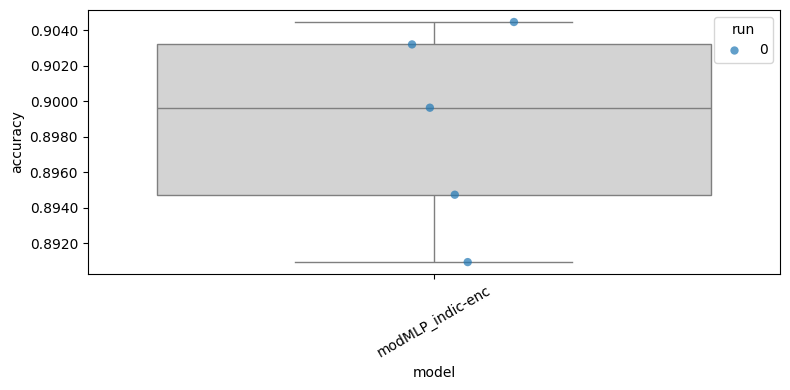

In [5]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [6]:
testing_sentences = test_dataset["sentence"]
testing_vectors = [indicator_encoder(text) for text in testing_sentences]
testing_labels = test_dataset["label"]
X_test_sparse = csr_matrix(testing_vectors)
test_dataset_sparse = mmlp.SparseDataset(X_test_sparse, testing_labels)

test_loader = DataLoader(
        test_dataset_sparse,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=mmlp.sparse_collate
    )

criterion = nn.BCEWithLogitsLoss()

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):    
        model_folder = f"{results_folder}/modMLP_indic-enc/seed-{seed}/fold-{fold}/model"
        model = mmlp.load(model_folder)

        mmlp.evaluate(model, test_loader, criterion, device)
        test_metrics, preds = mmlp.evaluate(model, test_loader, criterion, device)
        print(test_metrics)
        print(classification_report(testing_labels, preds))

{'loss': 0.77820409437932, 'accuracy': 0.7660550458715596}
              precision    recall  f1-score   support

           0       0.75      0.78      0.76       428
           1       0.78      0.76      0.77       444

    accuracy                           0.77       872
   macro avg       0.77      0.77      0.77       872
weighted avg       0.77      0.77      0.77       872

{'loss': 0.7684306387507588, 'accuracy': 0.783256880733945}
              precision    recall  f1-score   support

           0       0.80      0.75      0.77       428
           1       0.77      0.82      0.79       444

    accuracy                           0.78       872
   macro avg       0.78      0.78      0.78       872
weighted avg       0.78      0.78      0.78       872

{'loss': 0.6832245457063028, 'accuracy': 0.75}
              precision    recall  f1-score   support

           0       0.74      0.76      0.75       428
           1       0.76      0.74      0.75       444

    accuracy    

In [7]:
# save results
Path("metrics").mkdir(exist_ok=True)

df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)
df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)